<a href="https://colab.research.google.com/github/slimani-meriem/w2vec/blob/main/02_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys

REPO_URL = "https://github.com/slimani-meriem/w2vec.git"
REPO_DIR = "/content/w2vec"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull

sys.path.insert(0, f"{REPO_DIR}/src")

from data import *
from w2v import train_from_corpus
from eval_w2v import get_embeddings, evaluate, evaluate_runs

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 319 bytes | 106.00 KiB/s, done.
From https://github.com/slimani-meriem/w2vec
   457688a..af74901  main       -> origin/main
Updating 457688a..af74901
Fast-forward
 src/w2v.py | 1 -
 1 file changed, 1 deletion(-)


In [2]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

False 


In [ ]:
!ls -lh /content/drive/MyDrive/tp-ml-w2vec

total 133M
-rw------- 1 root root 133M Nov  1 08:53 dataset.json


# **Premières évaluations et pistes d'amélioration des performances**
Ce notebook a pour objectif de réaliser les premiers entraînements, de comparer les embeddings implémentés from scratch avec ceux de Gensim, et d'explorer différentes pistes pour améliorer les performances des embeddings Word2Vec.

In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import filter_rare_words, load_dataset
from w2v import w2v, save_embeddings
from eval_w2v import get_embeddings, evaluate

# --- Entrées (dépôt) ---
CORPUS   = f"{REPO_DIR}/data/Le_comte_de_Monte_Cristo.tok"
SIM_FILE = f"{REPO_DIR}/data/Le_comte_de_Monte_Cristo.100.sim.txt"

# --- Sorties (Drive, persistantes) ---
OUT_DIR      = "/content/drive/MyDrive/tp-ml-w2vec"
FILTERED     = f"{OUT_DIR}/filtered_text.txt"
DATASET_PATH = f"{OUT_DIR}/dataset.json"
RESULTS_CSV  = f"{OUT_DIR}/results.csv"
LOSSES_JSON  = f"{OUT_DIR}/losses.json"

# --- Hyperparamètres de l'énoncé ---
N = 100        # dimension des embeddings
ETA = 0.1      # taux d'apprentissage
E = 5          # nombre d'itérations
MINC = 5       # occurrences minimales
N_RUNS = 10

In [3]:
_, valid_words = filter_rare_words(CORPUS, FILTERED, minc=MINC)
dataset = load_dataset(DATASET_PATH)

print(f"Vocabulaire : {len(valid_words)} mots")
print(f"Dataset : {len(dataset)} exemples")

Vocabulaire : 3156 mots
Dataset : 876832 exemples


## **Partie 1 : Premiers entraînements**
### **1.1 Entraînement d'embeddings w2v**

In [ ]:
# test d'exécution
t0 = time.time()
W_test, losses_test = w2v(dataset, valid_words, n=N, max_iter=1, eta=ETA, seed=0)
dt = time.time() - t0
print(f"1 itération : {dt:.0f} s")
print(f"Estimation pour {N_RUNS} runs x {E} itérations : {dt * E * N_RUNS / 3600:.1f} h")

Itération 1/1 - perte moyenne : 3.0534
1 itération : 70 s
Estimation pour 10 runs x 5 itérations : 1.0 h


In [ ]:
rows = []
all_losses = {}

for seed in range(N_RUNS):          # changer la seed pour changer l'initialisation de W et des permutations dans les données d'entrainement
    out = f"{OUT_DIR}/embeddings_seed{seed}.txt"
    t0 = time.time()

    W, losses = w2v(dataset, valid_words, n=N, max_iter=E, eta=ETA, seed=seed)
    save_embeddings(W, valid_words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)

    rows.append({"seed": seed, "rate": res["rate"], "correct": res["correct"],
                 "total": res["total"], "oov": res["oov"],
                 "final_loss": losses[-1], "time_s": round(time.time() - t0)})
    all_losses[str(seed)] = losses

    print(f"seed {seed} : taux = {res['rate']:.3f} | perte finale = {losses[-1]:.3f} "
          f"| {rows[-1]['time_s']} s")

pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)
json.dump(all_losses, open(LOSSES_JSON, "w"))

Itération 1/5 - perte moyenne : 3.0534
Itération 2/5 - perte moyenne : 2.8751
Itération 3/5 - perte moyenne : 2.8358
Itération 4/5 - perte moyenne : 2.8190
Itération 5/5 - perte moyenne : 2.8111
seed 0 : taux = 0.760 | perte finale = 2.811 | 311 s
Itération 1/5 - perte moyenne : 3.0540
Itération 2/5 - perte moyenne : 2.8746
Itération 3/5 - perte moyenne : 2.8364
Itération 4/5 - perte moyenne : 2.8194
Itération 5/5 - perte moyenne : 2.8109
seed 1 : taux = 0.780 | perte finale = 2.811 | 308 s
Itération 1/5 - perte moyenne : 3.0541
Itération 2/5 - perte moyenne : 2.8747
Itération 3/5 - perte moyenne : 2.8357
Itération 4/5 - perte moyenne : 2.8198
Itération 5/5 - perte moyenne : 2.8104
seed 2 : taux = 0.760 | perte finale = 2.810 | 312 s
Itération 1/5 - perte moyenne : 3.0547
Itération 2/5 - perte moyenne : 2.8746
Itération 3/5 - perte moyenne : 2.8363
Itération 4/5 - perte moyenne : 2.8188
Itération 5/5 - perte moyenne : 2.8114
seed 3 : taux = 0.690 | perte finale = 2.811 | 310 s
Itératio

In [21]:
rows = []
all_losses = {}
all_loss_details = {}

for seed in range(N_RUNS):
    out = f"{OUT_DIR}/embeddings_piste_1_seed{seed}.txt"
    t0 = time.time()

    details = {}

    W, losses = w2v(
        dataset, valid_words, n=N, max_iter=E, eta=ETA,
        seed=seed, loss_details=details
    )

    save_embeddings(W, valid_words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)

    time_s = round(time.time() - t0)

    rows.append({
        "seed": seed,
        "rate": res["rate"],
        "correct": res["correct"],
        "total": res["total"],
        "oov": res["oov"],
        "final_loss": losses[-1],
        "final_loss_pos": details["pos"][-1],
        "final_loss_neg": details["neg"][-1],
        "time_s": time_s
    })

    all_losses[str(seed)] = losses
    all_loss_details[str(seed)] = details

    # Affichage des losses à chaque itération
    print(f"\n========== RUN seed={seed} ==========")
    print(f"{'Iteration':<12} {'Positive loss':<18} {'Negative loss':<18} {'Total loss':<18}")

    for i, (pos, neg, total) in enumerate(
        zip(details["pos"], details["neg"], losses), start=1
    ):
        print(f"{i:<12} {pos:<18.6f} {neg:<18.6f} {total:<18.6f}")

    print(
        f"\nTaux = {res['rate']:.3f} | "
        f"Perte finale = {losses[-1]:.3f} | Temps = {time_s} s"
    )

# Sauvegarde des résultats
pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)

json.dump(all_losses, open(LOSSES_JSON, "w"))
json.dump(
    all_loss_details,
    open(LOSSES_JSON.replace(".json", "_details.json"), "w")
)

Itération 1/5 - perte moyenne : 3.0534
Itération 2/5 - perte moyenne : 2.8751
Itération 3/5 - perte moyenne : 2.8358
Itération 4/5 - perte moyenne : 2.8190
Itération 5/5 - perte moyenne : 2.8111

========== RUN seed=0 ==========
Iteration    Positive loss      Negative loss      Total loss        
1            2.106477           0.946955           3.053432          
2            1.971796           0.903263           2.875059          
3            1.938054           0.897734           2.835788          
4            1.923234           0.895789           2.819024          
5            1.915784           0.895363           2.811147          

Taux = 0.760 | Perte finale = 2.811 | Temps = 368 s
Itération 1/5 - perte moyenne : 3.0540
Itération 2/5 - perte moyenne : 2.8746
Itération 3/5 - perte moyenne : 2.8364
Itération 4/5 - perte moyenne : 2.8194
Itération 5/5 - perte moyenne : 2.8109

========== RUN seed=1 ==========
Iteration    Positive loss      Negative loss      Total loss        

In [5]:
losses_finales = [
    2.811147, 2.810932, 2.810415, 2.811383, 2.811247,
    2.810862, 2.811587, 2.811214, 2.810918, 2.809832
]

print(f"Loss: {np.mean(losses_finales):.4} ± {np.std(losses_finales):.4}")

taux = [0.760, 0.780, 0.760, 0.690, 0.760,
        0.740, 0.780, 0.700, 0.750, 0.690]

print(f"Taux : {np.mean(taux):.4f} ± {np.std(taux):.4}")

Loss: 2.811 ± 0.0004832
Taux : 0.7410 ± 0.0333


In [15]:
# Décortiquer un seul run pour analyser l'origine des pertes élevées
seed = 0
out = f"{OUT_DIR}/embeddings_details_run_seed{seed}.txt"
t0 = time.time()

details = {}

W, losses = w2v(
    dataset, valid_words, n=N, max_iter=E, eta=ETA,
    seed=seed, loss_details=details
)

save_embeddings(W, valid_words, out)
res = evaluate(get_embeddings(out), SIM_FILE)

time_s = round(time.time() - t0)

# Résultats de l'évaluation
row = {
    "seed": seed,
    "rate": res["rate"],
    "correct": res["correct"],
    "total": res["total"],
    "oov": res["oov"],
    "final_loss": losses[-1],
    "final_loss_pos": details["pos"][-1],
    "final_loss_neg": details["neg"][-1],
    "time_s": time_s
}

# Sauvegarde des résultats
pd.DataFrame([row]).to_csv(RESULTS_CSV, index=False)

json.dump({"0": losses}, open(LOSSES_JSON, "w"))
json.dump({"0": details}, open(LOSSES_JSON.replace(".json", "_details.json"), "w"))

print(
    f"seed {seed} : taux = {res['rate']:.3f} | "
    f"perte finale = {losses[-1]:.3f} "
    f"(pos = {details['pos'][-1]:.3f}, "
    f"neg = {details['neg'][-1]:.3f}) "
    f"| {time_s} s"
)

Itération 1/5 - perte moyenne : 3.0534
Itération 2/5 - perte moyenne : 2.8751
Itération 3/5 - perte moyenne : 2.8358
Itération 4/5 - perte moyenne : 2.8190
Itération 5/5 - perte moyenne : 2.8111
seed 0 : taux = 0.760 | perte finale = 2.811 (pos = 1.916, neg = 0.895) | 380 s


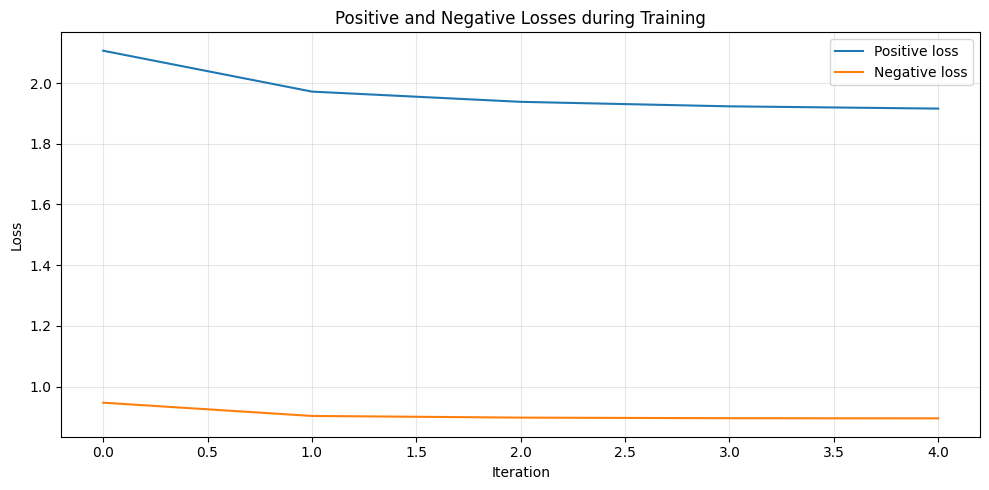

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(details["pos"], label="Positive loss")
plt.plot(details["neg"], label="Negative loss")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Positive and Negative Losses during Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
!cp /content/w2vec/data/filtered_text.txt /content/drive/MyDrive/tp-ml-w2vec//

### **1.2 Entraîner les embeddings Gensim**
Nous allons directement utiliser le texte prétraité : les mots dont la fréquence d'apparition est inférieure à minc ont déjà été éliminés, et tous les mots ont été convertis en minuscules. C'est pourquoi nous fixerons min_count à 1 pour Gensim, au lieu de 5 comme pour Word2Vec, afin de ne pas supprimer davantage de mots.

In [10]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 56.9 MB/s  0:00:00


In [11]:
from gensim.models import Word2Vec

WINDOW = 5      # pour Gensim, la taille de la fenête = contexte gauche + mot cible + contexte droit = 2*L + 1 = 5
K_NEG  = 5      # même nombre de négatifs k que dans le dataset utilisé dans w2v
MIN_COUNT = 1   # pour garder tous les mots et pas en supprimer davantage

# pour rappel : FILTERED chemin vers le fichier contenant le texte filtré (élimination des mots < minc)
with open(FILTERED, encoding="utf-8") as f:
    sentences = [line.split() for line in f if line.strip()]

print(len(sentences), "phrases")
print(sentences[:2])

9512 phrases
[['<s>', '<s>', 'le', 'février', '1815', ',', 'la', 'de', 'notre', '-', 'dame', 'de', 'la', 'garde', 'le', 'trois', '-', 'le', 'pharaon', ',', 'venant', 'de', 'smyrne', ',', 'et', 'naples', '.', '</s>', '</s>'], ['<s>', '<s>', 'comme', 'd’', 'habitude', ',', 'un', 'pilote', 'partit', 'aussitôt', 'du', 'port', ',', 'le', 'château', 'd’', 'if', ',', 'et', 'alla', 'aborder', 'le', 'navire', 'entre', 'le', 'cap', 'de', 'et', 'l’', 'île', 'de', '.', '</s>', '</s>']]


In [12]:
rows_gs = []
for seed in range(N_RUNS):
    out = f"{OUT_DIR}/gensim_embeddings_seed{seed}.txt"
    t0 = time.time()

    model = Word2Vec(
        sentences=sentences,
        vector_size=N,        # même dimension que pour w2v
        window=WINDOW,
        min_count=MIN_COUNT,
        sg=1,                 # skip-gram
        negative=K_NEG,       # negative sampling
        alpha=ETA,            # taux d'apprentissage initial
        epochs=E,
        seed=seed,
        workers=1,
    )

    # On enregistre les embeddings appris dans le même ordre que pour les embeddings w2v
    # model.wv étant la liste des embeddings appris (un dictionnaire)
    words = [w for w in valid_words if w in model.wv.key_to_index]
    W_gs = np.vstack([model.wv[w] for w in words])

    save_embeddings(W_gs, words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)

    rows_gs.append({"seed": seed, "rate": res["rate"], "correct": res["correct"],
                    "total": res["total"], "oov": res["oov"],
                    "n_words": len(words), "time_s": round(time.time() - t0)})
    print(f"[gensim] seed {seed} : taux = {res['rate']:.3f} | oov = {res['oov']} "
          f"| {rows_gs[-1]['time_s']} s")

df_gs = pd.DataFrame(rows_gs)
df_gs.to_csv(f"{OUT_DIR}/gensim_results.csv", index=False)
print(f"\nBaseline Gensim : taux moyen = {df_gs['rate'].mean():.3f} ± {df_gs['rate'].std():.3f}")

[gensim] seed 0 : taux = 0.860 | oov = 0 | 10 s
[gensim] seed 1 : taux = 0.840 | oov = 0 | 13 s
[gensim] seed 2 : taux = 0.890 | oov = 0 | 5 s
[gensim] seed 3 : taux = 0.840 | oov = 0 | 5 s
[gensim] seed 4 : taux = 0.860 | oov = 0 | 6 s
[gensim] seed 5 : taux = 0.800 | oov = 0 | 5 s
[gensim] seed 6 : taux = 0.830 | oov = 0 | 12 s
[gensim] seed 7 : taux = 0.810 | oov = 0 | 5 s
[gensim] seed 8 : taux = 0.860 | oov = 0 | 6 s
[gensim] seed 9 : taux = 0.850 | oov = 0 | 6 s

Baseline Gensim : taux moyen = 0.844 ± 0.026


## **Partie 2 : Exploration de pistes d'amélioration**

### Piste 1 : Changement de méthode d'initialisation de W

In [4]:
rows = []
all_losses = {}
all_loss_details = {}

for seed in range(N_RUNS):
    out = f"{OUT_DIR}/embeddings_piste_1_seed{seed}.txt"
    t0 = time.time()

    details = {}

    W, losses = w2v(
        dataset, valid_words, n=N, max_iter=E, eta=ETA,
        seed=seed, loss_details=details
    )

    save_embeddings(W, valid_words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)

    time_s = round(time.time() - t0)

    rows.append({
        "seed": seed,
        "rate": res["rate"],
        "correct": res["correct"],
        "total": res["total"],
        "oov": res["oov"],
        "final_loss": losses[-1],
        "final_loss_pos": details["pos"][-1],
        "final_loss_neg": details["neg"][-1],
        "time_s": time_s
    })

    all_losses[str(seed)] = losses
    all_loss_details[str(seed)] = details

    # Affichage des losses à chaque itération
    print(f"\n========== RUN seed={seed} ==========")
    print(f"{'Iteration':<12} {'Positive loss':<18} {'Negative loss':<18} {'Total loss':<18}")

    for i, (pos, neg, total) in enumerate(
        zip(details["pos"], details["neg"], losses), start=1
    ):
        print(f"{i:<12} {pos:<18.6f} {neg:<18.6f} {total:<18.6f}")

    print(
        f"\nTaux = {res['rate']:.3f} | "
        f"Perte finale = {losses[-1]:.3f} | Temps = {time_s} s"
    )

# Sauvegarde des résultats
pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)

json.dump(all_losses, open(LOSSES_JSON, "w"))
json.dump(
    all_loss_details,
    open(LOSSES_JSON.replace(".json", "_details.json"), "w")
)

Itération 1/5 - perte moyenne : 2.9471
Itération 2/5 - perte moyenne : 2.8205
Itération 3/5 - perte moyenne : 2.8073
Itération 4/5 - perte moyenne : 2.8009
Itération 5/5 - perte moyenne : 2.7971

========== RUN seed=0 ==========
Iteration    Positive loss      Negative loss      Total loss        
1            1.960576           0.986573           2.947149          
2            1.933888           0.886638           2.820525          
3            1.919277           0.888059           2.807337          
4            1.911277           0.889631           2.800908          
5            1.905936           0.891125           2.797061          

Taux = 0.770 | Perte finale = 2.797 | Temps = 385 s
Itération 1/5 - perte moyenne : 2.9475
Itération 2/5 - perte moyenne : 2.8200
Itération 3/5 - perte moyenne : 2.8067
Itération 4/5 - perte moyenne : 2.8008
Itération 5/5 - perte moyenne : 2.7968

========== RUN seed=1 ==========
Iteration    Positive loss      Negative loss      Total loss        

In [6]:
final_losses = [row["final_loss"] for row in rows]
rates = [row["rate"] for row in rows]

print(f"Losses : {np.mean(final_losses):.6f} ± {np.std(final_losses, ddof=1):.6f}")

print(f"Taux : {np.mean(rates)*100:.2f}% ± {np.std(rates, ddof=1)*100:.2f}%")

Losses : 2.796921 ± 0.000460
Taux : 75.50% ± 1.72%


In [11]:
import shutil, glob, os

DRIVE_DIR = "/content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1"   # dossier de destination
os.makedirs(DRIVE_DIR, exist_ok=True)

for f in glob.glob(f"{OUT_DIR}/embeddings_piste_1_seed*.txt"):
    shutil.copy(f, DRIVE_DIR)
    print("copié :", f)

copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed0.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed1.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed2.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed3.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed4.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed5.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed6.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed7.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed8.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed9.txt


### Piste 2 : Jouer sur le taux d'apprentissage

In [7]:
seed = 0
out = f"{OUT_DIR}/embeddings_details_run_seed{seed}.txt"
t0 = time.time()

details = {}

ETA_SMALLER = ETA/5
W, losses = w2v(
    dataset, valid_words, n=N, max_iter=E, eta=ETA_SMALLER, # on ne change que eta
    seed=seed, loss_details=details
)

save_embeddings(W, valid_words, out)
res = evaluate(get_embeddings(out), SIM_FILE)

time_s = round(time.time() - t0)

# Résultats de l'évaluation
row = {
    "seed": seed,
    "rate": res["rate"],
    "correct": res["correct"],
    "total": res["total"],
    "oov": res["oov"],
    "final_loss": losses[-1],
    "final_loss_pos": details["pos"][-1],
    "final_loss_neg": details["neg"][-1],
    "time_s": time_s
}

# Sauvegarde des résultats
pd.DataFrame([row]).to_csv(RESULTS_CSV, index=False)

json.dump({"0": losses}, open(LOSSES_JSON, "w"))
json.dump({"0": details}, open(LOSSES_JSON.replace(".json", "_details.json"), "w"))

print(
    f"seed {seed} : taux = {res['rate']:.3f} | "
    f"perte finale = {losses[-1]:.3f} "
    f"(pos = {details['pos'][-1]:.3f}, "
    f"neg = {details['neg'][-1]:.3f}) "
    f"| {time_s} s"
)

Itération 1/5 - perte moyenne : 3.1638
Itération 2/5 - perte moyenne : 2.7287
Itération 3/5 - perte moyenne : 2.6632
Itération 4/5 - perte moyenne : 2.6247
Itération 5/5 - perte moyenne : 2.5966
seed 0 : taux = 0.780 | perte finale = 2.597 (pos = 1.770, neg = 0.827) | 391 s


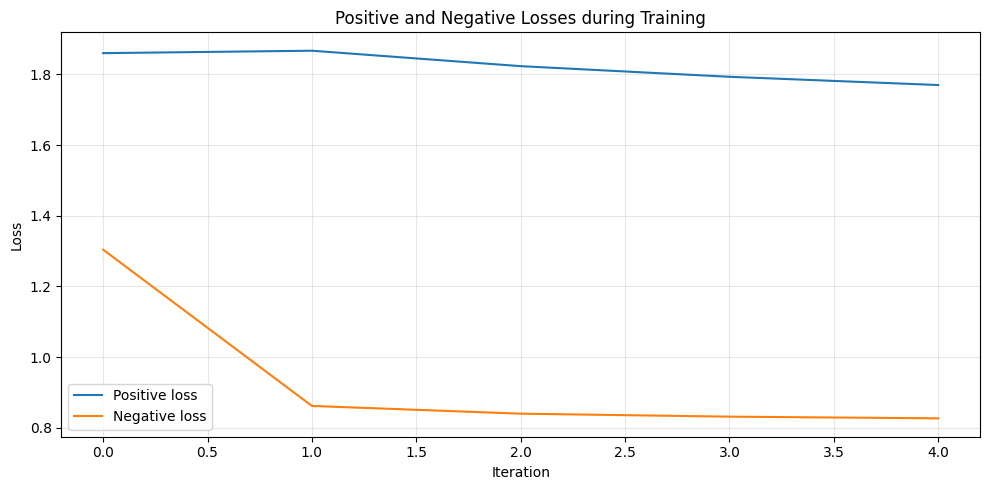

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(details["pos"], label="Positive loss")
plt.plot(details["neg"], label="Negative loss")
plt.plot(details["neg"], label="Total loss")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Positive and Negative Losses during Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
seed = 0
out = f"{OUT_DIR}/embeddings_details_run_seed{seed}.txt"
t0 = time.time()

details = {}

ETA_SMALLER = ETA/5
NEW_E = 3*E
W, losses = w2v(
    dataset, valid_words, n=N, max_iter=NEW_E, eta=ETA_SMALLER, # on ne change que eta + nombre d'iteration
    seed=seed, loss_details=details
)

save_embeddings(W, valid_words, out)
res = evaluate(get_embeddings(out), SIM_FILE)

time_s = round(time.time() - t0)

# Résultats de l'évaluation
row = {
    "seed": seed,
    "rate": res["rate"],
    "correct": res["correct"],
    "total": res["total"],
    "oov": res["oov"],
    "final_loss": losses[-1],
    "final_loss_pos": details["pos"][-1],
    "final_loss_neg": details["neg"][-1],
    "time_s": time_s
}

# Sauvegarde des résultats
pd.DataFrame([row]).to_csv(RESULTS_CSV, index=False)

json.dump({"0": losses}, open(LOSSES_JSON, "w"))
json.dump({"0": details}, open(LOSSES_JSON.replace(".json", "_details.json"), "w"))

print(
    f"seed {seed} : taux = {res['rate']:.3f} | "
    f"perte finale = {losses[-1]:.3f} "
    f"(pos = {details['pos'][-1]:.3f}, "
    f"neg = {details['neg'][-1]:.3f}) "
    f"| {time_s} s"
)

Itération 1/15 - perte moyenne : 3.1638
Itération 2/15 - perte moyenne : 2.7287
Itération 3/15 - perte moyenne : 2.6632
Itération 4/15 - perte moyenne : 2.6247
Itération 5/15 - perte moyenne : 2.5966
Itération 6/15 - perte moyenne : 2.5740
Itération 7/15 - perte moyenne : 2.5546
Itération 8/15 - perte moyenne : 2.5377
Itération 9/15 - perte moyenne : 2.5225
Itération 10/15 - perte moyenne : 2.5088
Itération 11/15 - perte moyenne : 2.4960
Itération 12/15 - perte moyenne : 2.4836
Itération 13/15 - perte moyenne : 2.4731
Itération 14/15 - perte moyenne : 2.4629
Itération 15/15 - perte moyenne : 2.4534
seed 0 : taux = 0.780 | perte finale = 2.453 (pos = 1.646, neg = 0.807) | 1118 s
